# College Admission Classification Example

Import libraries

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import csv


Read the data from the csv file   

In [33]:
df = pd.read_csv("College Admission Scores.csv", sep=';')


Plot the data

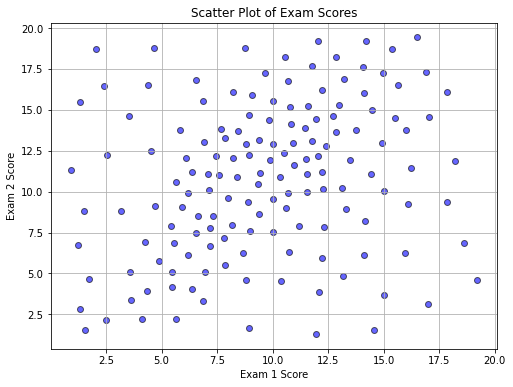

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(df['Exam1'], df['Exam2'], color='blue', alpha=0.6, edgecolors='k')
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Scatter Plot of Exam Scores')
plt.grid(True)
plt.show()

Calculatre the decision boundary based on the mean of the two exams

In [ ]:
mean_exam1 = df['Exam1'].mean()
mean_exam2 = df['Exam2'].mean()
print('Mean of Exam 1:', mean_exam1)
print('Mean of Exam 2:', mean_exam2)

Mean of Exam 1: 9.660933333333329
Mean of Exam 2: 10.759266666666674


Plot the data and color it using your calculated decision 

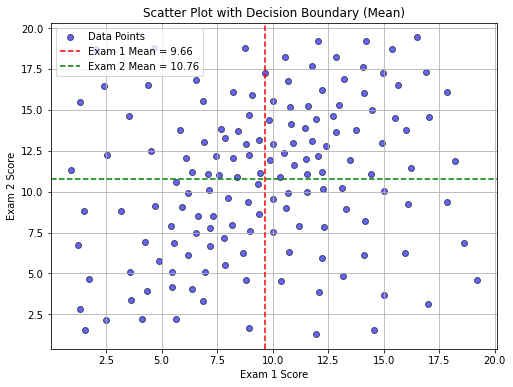

In [36]:
plt.figure(figsize=(8,6))
plt.scatter(df['Exam1'], df['Exam2'], color='blue', alpha=0.6, edgecolors='k', label="Data Points")

# Plotting the decision boundary (mean line)
plt.axvline(mean_exam1, color='red', linestyle='--', label=f'Exam 1 Mean = {mean_exam1:.2f}')
plt.axhline(mean_exam2, color='green', linestyle='--', label=f'Exam 2 Mean = {mean_exam2:.2f}')

plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Scatter Plot with Decision Boundary (Mean)')
plt.legend()
plt.grid(True)
plt.show()

Use a meshgrid to visualize the decision boundary as two spaces


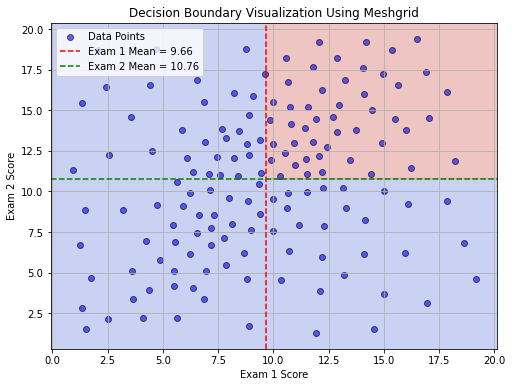

In [40]:
# Creating a meshgrid over the range of Exam 1 and Exam 2 scores
x_min, x_max = df['Exam1'].min() - 1, df['Exam1'].max() + 1
y_min, y_max = df['Exam2'].min() - 1, df['Exam2'].max() + 1
plot_step = 0.1

xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                     np.arange(y_min, y_max, plot_step))

# Creating a decision boundary based on the means
Z = ((xx > mean_exam1) & (yy > mean_exam2)).astype(int)  # Assigning regions based on mean

# Plotting the decision boundary regions
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, cmap="coolwarm", alpha=0.3)

# Scatter plot of original data
plt.scatter(df['Exam1'], df['Exam2'], color='blue', alpha=0.6, edgecolors='k', label="Data Points")

# Plotting the decision boundary lines
plt.axvline(mean_exam1, color='red', linestyle='--', label=f'Exam 1 Mean = {mean_exam1:.2f}')
plt.axhline(mean_exam2, color='green', linestyle='--', label=f'Exam 2 Mean = {mean_exam2:.2f}')

plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Decision Boundary Visualization Using Meshgrid')
plt.legend()
plt.grid(True)
plt.show()


Now, load the data file 'College Admission Scores and Decisions.csv'

In [41]:
df = pd.read_csv("College Admission Scores and Decisions.csv", sep=';')

Make the same previous plot by replacing the color of your points by the decision data

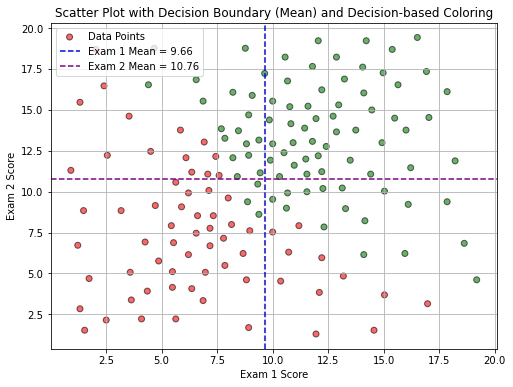

In [42]:
colors = {0: 'red', 1: 'green'}

# Plot scatter points with decision-based coloring
plt.figure(figsize=(8, 6))
plt.scatter(df['Exam1'], df['Exam2'], c=df['Decision'].map(colors), alpha=0.6, edgecolors='k', label="Data Points")

# Plot decision boundaries (mean lines)
mean_exam1 = df['Exam1'].mean()
mean_exam2 = df['Exam2'].mean()
plt.axvline(mean_exam1, color='blue', linestyle='--', label=f'Exam 1 Mean = {mean_exam1:.2f}')
plt.axhline(mean_exam2, color='purple', linestyle='--', label=f'Exam 2 Mean = {mean_exam2:.2f}')

# Labels and title
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Scatter Plot with Decision Boundary (Mean) and Decision-based Coloring')
plt.legend()
plt.grid(True)
plt.show()

# Linear Discriminant Analysis

Create an LDA classifier and fit it over your data

In [43]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
X = df[['Exam1', 'Exam2']]
y = df['Decision']

# Create and fit the LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

# Print LDA coefficients and intercept
print("LDA Coefficients:", lda.coef_)
print("LDA Intercept:", lda.intercept_)

LDA Coefficients: [[0.6659971  0.60427956]]
LDA Intercept: [-12.18677437]


Use a meshgrid to visualize the decision boundary of your LDA Classifier

c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


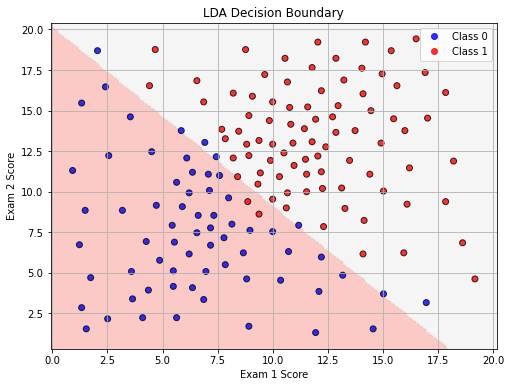

In [44]:
x_min, x_max = X['Exam1'].min() - 1, X['Exam1'].max() + 1
y_min, y_max = X['Exam2'].min() - 1, X['Exam2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict decision boundaries on the meshgrid
Z = lda.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="Pastel1", alpha=0.7)

# Plot the original data points
scatter = plt.scatter(X['Exam1'], X['Exam2'], c=y, cmap="bwr", edgecolors='k', alpha=0.8)
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('LDA Decision Boundary')

# Add legend
plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.grid(True)
plt.show()

What is its accuracy ?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and fit the LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

# Make predictions on the test set
y_pred = lda.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9000


What is the decision for a student with scores 19 and 0 ?

In [47]:
new_student = np.array([[19, 0]])

# Predict the decision using the trained LDA model
prediction = lda.predict(new_student)

# Display the predicted decision
print(f"The predicted decision for the student with Exam1 = 19 and Exam2 = 0 is: {prediction[0]}")

The predicted decision for the student with Exam1 = 19 and Exam2 = 0 is: 1


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


---
# Quadratic Discriminant Analysis

Same questions...

In [53]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
qda = QuadraticDiscriminantAnalysis()
qda.fit(X, y)
print("QDA model fitted successfully.")
print("Prior probabilities:", qda.priors_)
print("Means:", qda.means_)
# print("Covariance matrices:", qda.covariance_)

QDA model fitted successfully.
Prior probabilities: [0.43333333 0.56666667]
Means: [[ 6.56015385  7.41476923]
 [12.03211765 13.31682353]]


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but QuadraticDiscriminantAnalysis was fitted with feature names
  warnings.warn(


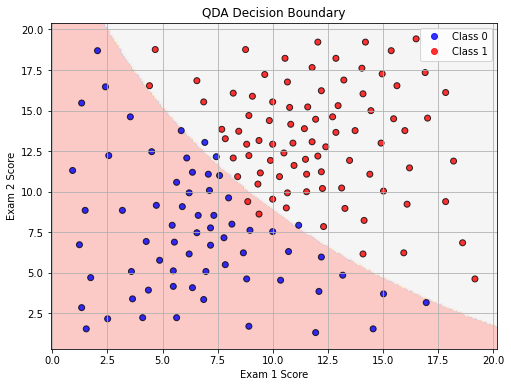

In [49]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(X, y)

# Create a meshgrid for visualization
x_min, x_max = X['Exam1'].min() - 1, X['Exam1'].max() + 1
y_min, y_max = X['Exam2'].min() - 1, X['Exam2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict decision boundaries on the meshgrid
Z = qda.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="Pastel1", alpha=0.7)

# Plot the original data points
scatter = plt.scatter(X['Exam1'], X['Exam2'], c=y, cmap="bwr", edgecolors='k', alpha=0.8)
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('QDA Decision Boundary')

# Add legend
plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.grid(True)
plt.show()

In [54]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and fit the QDA model
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

# Make predictions on the test set
y_pred = qda.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"QDA Accuracy: {accuracy:.4f}")


QDA Accuracy: 0.9333


In [55]:
new_student = np.array([[19, 0]])

# Predict the decision using the trained QDA model
prediction = qda.predict(new_student)

# Display the predicted decision
print(f"The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using QDA is: {prediction[0]}")

The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using QDA is: 0


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but QuadraticDiscriminantAnalysis was fitted with feature names
  warnings.warn(


---
# Decisision Tree Classifier

Same questions

In [58]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

# Fit the model to the data
dt.fit(X, y)

# Display the model parameters
print("Decision Tree model fitted successfully.")

Decision Tree model fitted successfully.


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


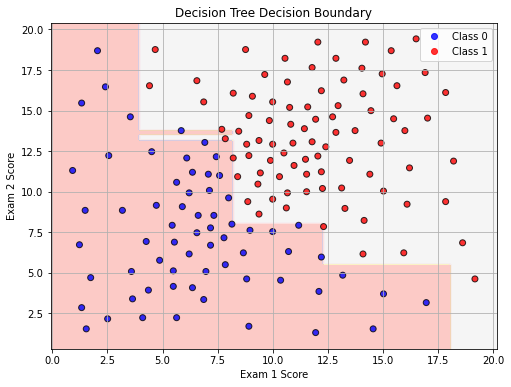

In [59]:
x_min, x_max = X['Exam1'].min() - 1, X['Exam1'].max() + 1
y_min, y_max = X['Exam2'].min() - 1, X['Exam2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict decision boundaries on the meshgrid
Z = dt.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="Pastel1", alpha=0.7)

# Plot the original data points
scatter = plt.scatter(X['Exam1'], X['Exam2'], c=y, cmap="bwr", edgecolors='k', alpha=0.8)
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Decision Tree Decision Boundary')

# Add legend
plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.grid(True)
plt.show()

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the Decision Tree model to the training data
dt.fit(X_train, y_train)

# Predict on the test set
y_pred = dt.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Accuracy: {accuracy:.4f}")

Decision Tree Accuracy: 0.8667


In [61]:
new_student = np.array([[19, 0]])

# Predict the decision using the trained Decision Tree model
prediction = dt.predict(new_student)

# Display the predicted decision
print(f"The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using Decision Tree is: {prediction[0]}")

The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using Decision Tree is: 0


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


---

# K-Nearest Neighbors Classifier (KNN)

Same questions

In [62]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

# Fit the model to the data
knn.fit(X, y)

# Display the model parameters
print("KNN model fitted successfully.")

KNN model fitted successfully.


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


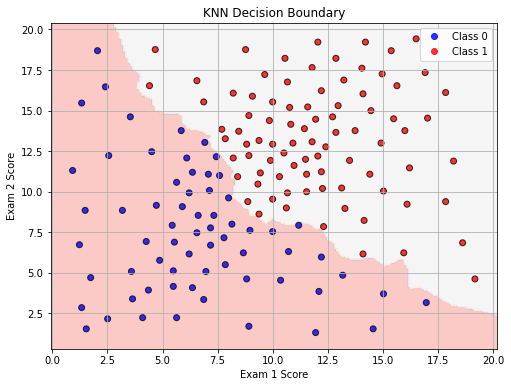

In [63]:
x_min, x_max = X['Exam1'].min() - 1, X['Exam1'].max() + 1
y_min, y_max = X['Exam2'].min() - 1, X['Exam2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict decision boundaries on the meshgrid using KNN
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="Pastel1", alpha=0.7)

# Plot the original data points
scatter = plt.scatter(X['Exam1'], X['Exam2'], c=y, cmap="bwr", edgecolors='k', alpha=0.8)
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('KNN Decision Boundary')

# Add legend
plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.grid(True)
plt.show()


In [64]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the KNN model to the training data
knn.fit(X_train, y_train)

# Predict on the test set
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"KNN Accuracy: {accuracy:.4f}")

KNN Accuracy: 1.0000


In [65]:
new_student = np.array([[19, 0]])

# Predict the decision using the trained KNN model
prediction = knn.predict(new_student)

# Display the predicted decision
print(f"The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using KNN is: {prediction[0]}")

The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using KNN is: 0


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


---
# Random Forest Classifier

Same questions...

In [66]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model to the data
rf.fit(X, y)

# Display the model parameters
print("Random Forest model fitted successfully.")


Random Forest model fitted successfully.


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


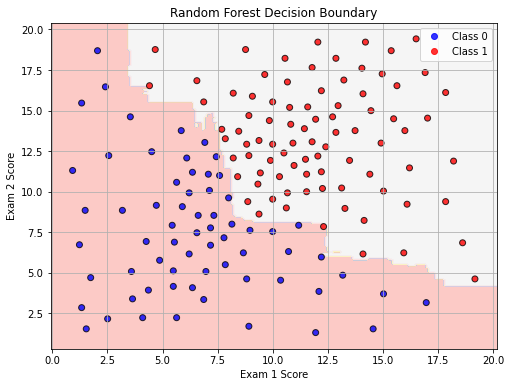

In [67]:
x_min, x_max = X['Exam1'].min() - 1, X['Exam1'].max() + 1
y_min, y_max = X['Exam2'].min() - 1, X['Exam2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict decision boundaries on the meshgrid using Random Forest
Z = rf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="Pastel1", alpha=0.7)

# Plot the original data points
scatter = plt.scatter(X['Exam1'], X['Exam2'], c=y, cmap="bwr", edgecolors='k', alpha=0.8)
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.title('Random Forest Decision Boundary')

# Add legend
plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.grid(True)
plt.show()

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the Random Forest model to the training data
rf.fit(X_train, y_train)

# Predict on the test set
y_pred = rf.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy:.4f}")

Random Forest Accuracy: 0.9000


In [69]:
new_student = np.array([[19, 0]])

# Predict the decision using the trained Random Forest model
prediction = rf.predict(new_student)

# Display the predicted decision
print(f"The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using Random Forest is: {prediction[0]}")

The predicted decision for the student with Exam1 = 19 and Exam2 = 0 using Random Forest is: 0


c:\Users\Asus\anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
